<a href="https://colab.research.google.com/github/ttobias28/PhishRadar-Project/blob/distilBert/PhishRadar_DistilBERT_SourceInvariant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PhishRadar — Experiment A: Source-invariant DistilBERT

**The question:** the model trains on only three collections (Enron, Ling, SpamAssassin), and each has its own writing style *and* its own share of phishing (Enron ~47%, SpamAssassin ~26%, Ling ~16%). So "which collection does this email look like?" is a shortcut that partly predicts the label. Shortcuts like that don't carry over to new sources such as CEAS or Nazario. **If we take the shortcut away, do the cross-source scores improve?**

**Three versions are trained with identical settings, data and random seed:**

| Version | What changes |
|---|---|
| `baseline` | Plain fine-tuning, same as the main notebook. The control. |
| `balanced` | Each (source, label) combination counts equally in training, so the source no longer predicts the label. |
| `source_invariant` | Balanced **plus** an adversary: a small extra network tries to guess the source from BERT's internal summary of the email, and BERT is trained to make it fail. |

Comparing `balanced` with `source_invariant` shows whether the adversary adds anything beyond balancing. All three are scored on the same five test sets as the main notebook.

**Every time (Google Colab):**
1. Open this notebook in Colab (colab.research.google.com → **File → Upload notebook**).
2. **Runtime → Change runtime type → T4 GPU**.
3. Click the folder icon in the left sidebar and drag in the splits zip (`phishradar_splits_1.zip`). Wait for the upload to finish.
4. **Runtime → Run all**, and keep the tab open.
5. At the end, download the result files and the model (step 15).

**Run it twice:** this notebook uses custom training code, so first run it with `SAMPLE_SIZE = 5000` (about 15 minutes) to make sure everything works. Then set `SAMPLE_SIZE = None` for the real experiment. With all three versions on the full data, expect roughly 1.5–2 hours; drop `"balanced"` from `VARIANTS` to save about a third of that.

## 1. Install libraries

In [ ]:
%pip install -q transformers datasets accelerate scikit-learn seaborn

## 2. Imports and GPU check

In [ ]:
import os, re, sys, glob, zipfile, math, shutil, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_fscore_support, accuracy_score,
                             confusion_matrix, balanced_accuracy_score)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)

IN_COLAB = "google.colab" in sys.modules
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_FP16 = device.type == "cuda"
print("Running in Colab:", IN_COLAB)
print("Device:", torch.cuda.get_device_name(0) if USE_FP16 else "CPU (no GPU! Runtime -> Change runtime type -> T4 GPU)")

Running in Colab: True
Device: Tesla T4


## 3. Settings
The first block uses the same settings as the main notebook. This notebook has its own training loop (it needs one for the adversary), so its `baseline` can differ slightly from your main DistilBERT run. **Compare the three versions in this notebook with each other**; the main notebook's run stays the official DistilBERT result for the team's three-way comparison.

The second block is new:
- **VARIANTS**: which versions to train, in order.
- **ADV_WEIGHT**: how hard BERT is pushed to hide the source (0 = not at all). 1.0 is a standard starting point. If cross-source scores drop, try 0.3; if the source probe in step 12 still finds the source easily, try 2.0.
- **ADV_LR**: learning rate for the adversary. It starts from scratch, so it learns faster than BERT.
- **MAX_WEIGHT**: cap on how much one rare email can count when balancing (e.g. Ling's few phishing emails), so a handful of emails can't dominate training.
- **SAVE_VARIANT**: which trained model to download at the end.

In [ ]:
MODEL_NAME        = "distilbert-base-uncased"
MAX_LENGTH        = 256
EPOCHS            = 2
LEARNING_RATE     = 2e-5
BATCH_SIZE        = 16
SEED              = 42
SAMPLE_SIZE       = 5000    # first run: 5000 to check it works; then None for the real experiment
NORMALIZE_SPACING = True

VARIANTS          = ["baseline", "source_invariant"]
ADV_WEIGHT        = 1.0
ADV_LR            = 1e-3
MAX_WEIGHT        = 10.0
SAVE_VARIANT      = "source_invariant"
DOWNLOAD_MODEL    = True

DATA_DIR = "/content/data" if IN_COLAB else "data"
OUT_DIR  = "/content" if IN_COLAB else "."
TEST_SETS = ["test_insource", "test_ceas", "test_nazario_paired", "test_nazario", "test_nigerian"]

## 4. Load the data
Drag the splits zip into the **Files panel** before running this cell. This cell finds it and unzips it. (Running in plain Jupyter? Put the CSVs in a folder called `data` next to this notebook.)

In [ ]:
found = glob.glob(os.path.join(DATA_DIR, "**", "train.csv"), recursive=True)
if not found and IN_COLAB:
    zips = [z for z in glob.glob("/content/*.zip")
            if any(n.endswith("train.csv") for n in zipfile.ZipFile(z).namelist())]
    if not zips:
        raise FileNotFoundError("No data zip found. Drag phishradar_splits_1.zip into the Files panel "
                                "(folder icon, left sidebar), wait for the upload to finish, then rerun this cell.")
    print("Found", zips[0], "- unzipping...")
    zipfile.ZipFile(zips[0]).extractall(DATA_DIR)
    found = glob.glob(os.path.join(DATA_DIR, "**", "train.csv"), recursive=True)
if not found:
    raise FileNotFoundError(f"Put the split CSVs in a folder called '{DATA_DIR}' next to this notebook.")
DATA_DIR = os.path.dirname(found[0])

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
val_df   = pd.read_csv(os.path.join(DATA_DIR, "val.csv"))
tests    = {name: pd.read_csv(os.path.join(DATA_DIR, f"{name}.csv")) for name in TEST_SETS}

print(f"{'train':>20}: {len(train_df):>6,} emails, {train_df.label.mean():.0%} phishing")
print(f"{'val':>20}: {len(val_df):>6,} emails, {val_df.label.mean():.0%} phishing")
for name, d in tests.items():
    print(f"{name:>20}: {len(d):>6,} emails, {d.label.mean():.0%} phishing")

               train: 30,217 emails, 42% phishing
                 val:  3,778 emails, 42% phishing
       test_insource:  3,778 emails, 42% phishing
           test_ceas: 38,748 emails, 55% phishing
 test_nazario_paired:  3,088 emails, 50% phishing
        test_nazario:  1,544 emails, 100% phishing
       test_nigerian:  3,243 emails, 100% phishing


## 5. Fix the spaced-punctuation quirk
Same fix as the main notebook: Enron and Ling were stored as `doesn ' t , and`, while every test source uses normal punctuation. This removes the most obvious style difference before the model ever sees it.

In [ ]:
def normalize_spacing(t):
    t = re.sub(r"(\w) ' (s|t|re|ve|ll|d|m)\b", r"\1'\2", t)   # doesn ' t -> doesn't
    t = re.sub(r"\s+([,.;:!?%)\]}])", r"\1", t)                # word , -> word,
    t = re.sub(r"([(\[{$])\s+", r"\1", t)                      # ( word -> (word
    t = re.sub(r"(\d) ([.,:/]) (\d)", r"\1\2\3", t)             # 6 / 10 -> 6/10
    t = re.sub(r"(\d)([.,:/]) (\d)", r"\1\2\3", t)
    return t

if NORMALIZE_SPACING:
    for d in [train_df, val_df, *tests.values()]:
        d["text"] = d["text"].map(normalize_spacing)

if SAMPLE_SIZE:
    train_df = train_df.sample(n=min(SAMPLE_SIZE, len(train_df)), random_state=SEED)
    val_df   = val_df.sample(n=min(SAMPLE_SIZE // 5, len(val_df)), random_state=SEED)
print(f"Training on {len(train_df):,} emails, validating on {len(val_df):,}")

Training on 5,000 emails, validating on 1,000


## 6. The shortcut, in numbers
This table is the problem in one picture: the share of phishing differs a lot by source, so a model that recognizes the source can guess the label without understanding phishing.

In [ ]:
shortcut = train_df.groupby("source").label.agg(emails="size", phishing_share="mean").round(3)
shortcut

,emails,phishing_share
source,,
Enron,3909,0.470
Ling,364,0.170
SpamAssassin,727,0.265


## 7. Balancing weights
Each email gets a weight so that every (source, label) combination counts the same in total. After weighting, every source is effectively 50% phishing, so knowing the source tells the model nothing about the label.

Rare combinations (like Ling phishing) get big weights; `MAX_WEIGHT` caps them. The table shows each combination's total weight after balancing; they should come out roughly equal.

In [ ]:
TRAIN_SOURCES = sorted(train_df.source.unique())
src2id = {s: i for i, s in enumerate(TRAIN_SOURCES)}

cell_size = train_df.groupby(["source", "label"])["label"].transform("size")
w = 1.0 / cell_size
w = w / w.mean()
w = w.clip(upper=MAX_WEIGHT)
train_df["weight"] = w / w.mean()
train_df["source_id"] = train_df.source.map(src2id)

train_df.groupby(["source", "label"]).weight.agg(emails="size", weight_each="mean", total_weight="sum").round(2)

emails  weight_each  total_weight
source       label                                   
Enron        0        2072         0.42        870.47
             1        1837         0.47        870.47
Ling         0         302         2.88        870.47
             1          62        10.45        647.63
SpamAssassin 0         534         1.63        870.47
             1         193         4.51        870.47

## 8. Tokenize
Same as the main notebook. The training set also carries each email's `weight` and `source_id` for the new training loop.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
collator = DataCollatorWithPadding(tokenizer)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

def to_dataset(frame, extra=()):
    ds = Dataset.from_pandas(frame[["text", "label", *extra]], preserve_index=False)
    return ds.map(tokenize, batched=True, remove_columns=["text"])

train_ds = to_dataset(train_df, extra=("weight", "source_id"))
val_ds   = to_dataset(val_df)
test_ds  = {name: to_dataset(d) for name, d in tests.items()}
train_ds

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3778 [00:00<?, ? examples/s]

Map:   0%|          | 0/38748 [00:00<?, ? examples/s]

Map:   0%|          | 0/3088 [00:00<?, ? examples/s]

Map:   0%|          | 0/1544 [00:00<?, ? examples/s]

Map:   0%|          | 0/3243 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'weight', 'source_id', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 5000
})

## 9. The adversary
Two small pieces of new machinery:

- **Gradient reversal.** On the way forward it does nothing. On the way back (when the model learns), it flips the sign of the learning signal. So the adversary learns to *guess* the source, while BERT, below it, learns to make that guess *harder*.
- **Class-conditional.** The adversary guesses the source **among emails with the same label** (phishing vs. phishing, legit vs. legit). That way BERT hides the source *style* without having to hide whether an email is phishing, which is the part we want it to keep.

The adversary is only used during training. The saved model is a normal DistilBERT classifier that loads exactly like the main notebook's model.

In [ ]:
class GradReverse(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, strength):
        ctx.strength = strength
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad):
        return -ctx.strength * grad, None


class SourceAdversary(nn.Module):
    def __init__(self, hidden_size, n_sources):
        super().__init__()
        self.n_sources = n_sources
        self.net = nn.Sequential(nn.Linear(hidden_size, 512), nn.ReLU(), nn.Dropout(0.1),
                                 nn.Linear(512, 512), nn.ReLU(), nn.Dropout(0.1),
                                 nn.Linear(512, 2 * n_sources))

    def forward(self, cls_vec, labels, strength):
        logits = self.net(GradReverse.apply(cls_vec, strength)).view(-1, 2, self.n_sources)
        return logits[torch.arange(len(labels), device=labels.device), labels]   # guess within the true label

## 10. Scoring helpers
Same metrics as the main notebook, plus a function that runs a model over a dataset and returns its phishing probabilities.

In [ ]:
def score(labels, preds):
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(labels, preds), "precision": p, "recall": r, "f1": f1,
            "false_positive_rate": fp / (fp + tn) if (fp + tn) else float("nan")}

@torch.no_grad()
def run_model(model, ds, want_embeddings=False):
    model.eval()
    loader = DataLoader(ds.select_columns(["input_ids", "attention_mask"]),
                        batch_size=128, collate_fn=collator)
    probs, embs = [], []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_FP16):
            out = model(**batch, output_hidden_states=want_embeddings)
        probs.append(torch.softmax(out.logits.float(), dim=-1)[:, 1].cpu().numpy())
        if want_embeddings:
            embs.append(out.hidden_states[-1][:, 0].float().cpu().numpy())
    probs = np.concatenate(probs)
    return (probs, np.concatenate(embs)) if want_embeddings else probs

## 11. The training loop
One function trains any of the three versions:
- `baseline`: every email counts the same; no adversary.
- `balanced`: uses the weights from step 7; no adversary.
- `source_invariant`: weights **and** adversary. The adversary's strength ramps up from 0 to `ADV_WEIGHT` during training, so BERT first learns the task and then learns to hide the source.

Every 200 steps it prints the task loss and, for `source_invariant`, the adversary's **balanced accuracy** at guessing the source (chance is about 0.33 with three sources). If BERT is hiding the source well, that number drifts down toward chance over training.

Each version starts from the same pre-trained DistilBERT and the same random seed, so the only difference is the training method.

In [ ]:
def train_variant(name):
    use_weights = name in ("balanced", "source_invariant")
    use_adv = name == "source_invariant"
    torch.manual_seed(SEED); np.random.seed(SEED)

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label={0: "legit", 1: "phishing"}, label2id={"legit": 0, "phishing": 1}).to(device)
    adversary = SourceAdversary(model.config.hidden_size, len(TRAIN_SOURCES)).to(device)

    groups = [{"params": model.parameters(), "lr": LEARNING_RATE}]
    if use_adv:
        groups.append({"params": adversary.parameters(), "lr": ADV_LR})
    optimizer = torch.optim.AdamW(groups, weight_decay=0.01)

    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collator,
                        generator=torch.Generator().manual_seed(SEED))
    total_steps = EPOCHS * len(loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.06 * total_steps), total_steps)
    scaler = torch.amp.GradScaler(device.type, enabled=USE_FP16)

    step, start = 0, time.time()
    for epoch in range(EPOCHS):
        model.train(); adversary.train()
        log = {"task": 0.0, "adv": 0.0, "hit": 0.0, "wsum": 0.0, "n": 0}
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch["labels"]
            weights = batch["weight"].float() if use_weights else torch.ones_like(labels, dtype=torch.float)
            strength = ADV_WEIGHT * (2 / (1 + math.exp(-10 * step / total_steps)) - 1)

            with torch.autocast(device.type, dtype=torch.float16, enabled=USE_FP16):
                out = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"],
                            output_hidden_states=use_adv)
            task_loss = (F.cross_entropy(out.logits.float(), labels, reduction="none") * weights).mean()
            loss = task_loss
            if use_adv:
                cls_vec = out.hidden_states[-1][:, 0].float()
                src_logits = adversary(cls_vec, labels, strength)
                adv_loss = (F.cross_entropy(src_logits, batch["source_id"], reduction="none") * weights).mean()
                loss = loss + adv_loss
                hit = (src_logits.argmax(-1) == batch["source_id"]).float()
                log["adv"] += adv_loss.item(); log["hit"] += (hit * weights).sum().item(); log["wsum"] += weights.sum().item()

            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(list(model.parameters()) + list(adversary.parameters()), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            step += 1; log["task"] += task_loss.item(); log["n"] += 1

            if step % 200 == 0 or step == total_steps:
                msg = f"  [{name}] step {step}/{total_steps}  task loss {log['task'] / log['n']:.4f}"
                if use_adv:
                    msg += f"  | adversary source accuracy {log['hit'] / max(log['wsum'], 1e-9):.2f} (strength {strength:.2f})"
                print(msg + f"  | {(time.time() - start) / 60:.1f} min", flush=True)
                log = {"task": 0.0, "adv": 0.0, "hit": 0.0, "wsum": 0.0, "n": 0}

        val_probs = run_model(model, val_ds)
        m = score(val_df.label.values, (val_probs >= 0.5).astype(int))
        print(f"  [{name}] epoch {epoch + 1}: validation F1 {m['f1']:.4f}, accuracy {m['accuracy']:.4f}", flush=True)
    return model

## 12. Train and score every version
For each version this cell: trains it, scores all five test sets, and runs a **source probe**. The probe takes BERT's internal summary of each validation email and checks how well a simple classifier can still tell which source it came from (balanced accuracy, chance ≈ 0.33). A lower probe score means the model really did stop encoding the source.

This is the long cell. Keep the tab open and your computer awake.

In [ ]:
rows, all_preds, probe_rows = [], [], []
for name in VARIANTS:
    print(f"\n=== Training {name} ===")
    model = train_variant(name)

    for test_name, d in tests.items():
        probs = run_model(model, test_ds[test_name])
        preds = (probs >= 0.5).astype(int)
        m = score(d.label.values, preds)
        if d.label.nunique() == 1:                       # phishing-only set: only recall is meaningful
            m.update(precision=float("nan"), f1=float("nan"))
        rows.append({"variant": name, "test_set": test_name, "emails": len(d), **m})
        all_preds.append(pd.DataFrame({"variant": name, "test_set": test_name, "row": np.arange(len(d)),
                                       "label": d.label.values, "source": d.source.values,
                                       "pred": preds, "phish_prob": probs}))

    _, emb = run_model(model, val_ds, want_embeddings=True)
    probe_scores = []
    for lab in (0, 1):                                   # probe within each label, like the adversary
        mask = val_df.label.values == lab
        e_tr, e_te, s_tr, s_te = train_test_split(emb[mask], val_df.source.values[mask], test_size=0.5,
                                                  stratify=val_df.source.values[mask], random_state=SEED)
        probe = LogisticRegression(max_iter=2000, class_weight="balanced").fit(e_tr, s_tr)
        probe_scores.append(balanced_accuracy_score(s_te, probe.predict(e_te)))
    probe_rows.append({"variant": name, "source_probe_balanced_acc": float(np.mean(probe_scores))})
    print(f"  [{name}] source probe balanced accuracy: {probe_rows[-1]['source_probe_balanced_acc']:.3f}")

    if name == SAVE_VARIANT:
        save_dir = os.path.join(OUT_DIR, f"distilbert-{name.replace('_', '-')}")
        model.save_pretrained(save_dir); tokenizer.save_pretrained(save_dir)
        print("  Saved model to", save_dir)
    del model
    if USE_FP16:
        torch.cuda.empty_cache()

results = pd.DataFrame(rows)
predictions = pd.concat(all_preds, ignore_index=True)
probe_table = pd.DataFrame(probe_rows).set_index("variant").round(3)
print("\nDone.")


=== Training baseline ===


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [baseline] step 200/626  task loss 0.2567  | 0.5 min
  [baseline] epoch 1: validation F1 0.9530, accuracy 0.9630
  [baseline] step 400/626  task loss 0.0428  | 0.9 min
  [baseline] step 600/626  task loss 0.0359  | 1.3 min
  [baseline] step 626/626  task loss 0.0412  | 1.3 min
  [baseline] epoch 2: validation F1 0.9741, accuracy 0.9790
  [baseline] source probe balanced accuracy: 0.690

=== Training source_invariant ===


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [source_invariant] step 200/626  task loss 0.3387  | adversary source accuracy 0.41 (strength 0.92)  | 0.4 min
  [source_invariant] epoch 1: validation F1 0.9428, accuracy 0.9550
  [source_invariant] step 400/626  task loss 0.0655  | adversary source accuracy 0.34 (strength 1.00)  | 0.8 min
  [source_invariant] step 600/626  task loss 0.0686  | adversary source accuracy 0.36 (strength 1.00)  | 1.2 min
  [source_invariant] step 626/626  task loss 0.1727  | adversary source accuracy 0.45 (strength 1.00)  | 1.3 min
  [source_invariant] epoch 2: validation F1 0.9547, accuracy 0.9640
  [source_invariant] source probe balanced accuracy: 0.641


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Saved model to /content/distilbert-source-invariant

Done.


## 13. Results side by side
**How to read this table:** each column is a version, each row a test set. The number is **F1** for the mixed test sets, and **recall** (detection rate) for the phishing-only sets (`test_nazario`, `test_nigerian`), where F1 doesn't apply.

What would support the idea: `source_invariant` (and/or `balanced`) beating `baseline` on the cross-source rows (`test_ceas`, `test_nazario_paired`, `test_nazario`, `test_nigerian`), even if `test_insource` drops slightly. A small in-source drop is expected: the shortcut *did* help on the training sources.

Also check the false-positive rates below: a model can raise recall just by flagging more emails as phishing.

In [ ]:
results["headline"] = np.where(results.f1.isna(), results.recall, results.f1)
headline = results.pivot(index="test_set", columns="variant", values="headline").reindex(index=TEST_SETS, columns=VARIANTS).round(4)
fpr = results.pivot(index="test_set", columns="variant", values="false_positive_rate").reindex(index=TEST_SETS, columns=VARIANTS).round(4)
print("F1 (mixed sets) / recall (phishing-only sets):")
display(headline)
print("\nFalse-positive rate (lower is better; blank = no legit emails in that set):")
display(fpr.dropna(how="all"))
print("\nSource probe (lower = less source information left; chance is about 0.33):")
display(probe_table)

F1 (mixed sets) / recall (phishing-only sets):


variant,baseline,source_invariant
test_set,,
test_insource,0.9750,0.9591
test_ceas,0.8879,0.8753
test_nazario_paired,0.9030,0.8658
test_nazario,0.8744,0.8005
test_nigerian,0.9895,0.8874



False-positive rate (lower is better; blank = no legit emails in that set):


variant,baseline,source_invariant
test_set,,
test_insource,0.0146,0.0141
test_ceas,0.0594,0.0425
test_nazario_paired,0.0622,0.0486



Source probe (lower = less source information left; chance is about 0.33):


,source_probe_balanced_acc
variant,
baseline,0.690
source_invariant,0.641


## 14. Chart

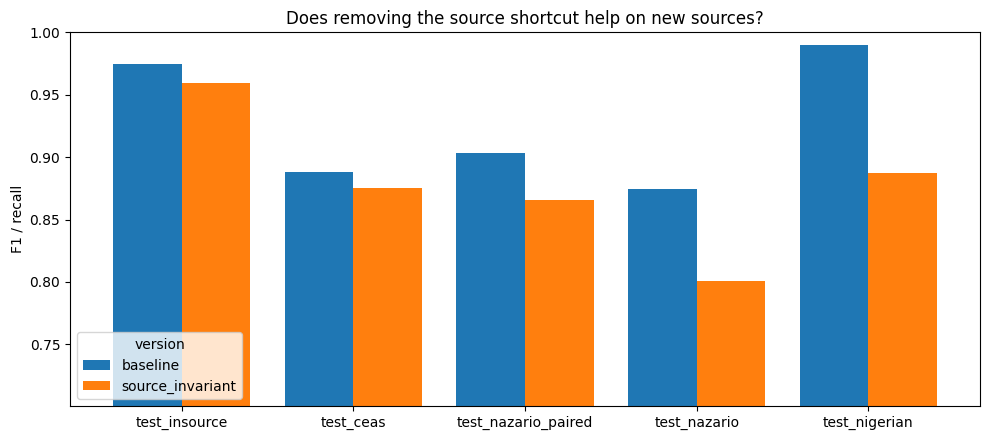

In [ ]:
ax = headline.plot.bar(figsize=(10, 4.5), rot=0, width=0.8)
ax.set_ylabel("F1 / recall"); ax.set_xlabel("")
ax.set_ylim(max(0, headline.min().min() - 0.1), 1.0)
ax.set_title("Does removing the source shortcut help on new sources?")
ax.legend(title="version", loc="lower left")
plt.tight_layout(); plt.show()

## 15. Save and download
This saves three files for GitHub and the model:
- `si_results.csv`: every score for every version and test set (small, for GitHub).
- `si_predictions.csv`: one row per test email per version, same columns as `bert_predictions.csv` plus `variant` (small enough for GitHub, ~5–8 MB).
- `si_probe.csv`: the source-probe scores.
- `distilbert-source-invariant.zip`: the trained model (~250 MB). Keep it on your computer, **not** GitHub. It loads in the main notebook with `LOAD_SAVED_MODEL = True`.

If any download doesn't arrive, use the Files panel: refresh, then ⋮ → **Download**. Don't close the tab until you have everything.

In [ ]:
results.drop(columns="headline").round(4).to_csv("si_results.csv", index=False)
predictions.to_csv("si_predictions.csv", index=False)
probe_table.to_csv("si_probe.csv")
to_download = ["si_results.csv", "si_predictions.csv", "si_probe.csv"]

save_dir = os.path.join(OUT_DIR, f"distilbert-{SAVE_VARIANT.replace('_', '-')}")
if DOWNLOAD_MODEL and os.path.exists(save_dir):
    shutil.make_archive(save_dir, "zip", save_dir)          # zip first, so it exists even if a download fails
    print(f"Model zipped: {save_dir}.zip ({os.path.getsize(save_dir + '.zip') // 1_000_000} MB)")
    to_download.insert(0, save_dir + ".zip")

if IN_COLAB:
    from google.colab import files
    for f in to_download:
        try:
            files.download(f)
        except Exception as e:
            print(f"Couldn't auto-download {f} ({e}).")
    print("If a file didn't arrive, download it from the Files panel (refresh, then ⋮ -> Download).")
else:
    print("Saved:", to_download)

Model zipped: /content/distilbert-source-invariant.zip (247 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

If a file didn't arrive, download it from the Files panel (refresh, then ⋮ -> Download).


## What to write up
1. **The shortcut table (step 6)**: why source style could be a shortcut in this data.
2. **The headline table and chart (steps 13–14)**: did cross-source scores improve? By how much, and at what cost to in-source scores and false positives?
3. **The probe (step 13)**: did the source-invariant model actually stop encoding the source? If the probe drops but the scores don't improve, the shortcut wasn't what limited cross-source performance, which is a finding too.
4. **Balanced vs. source_invariant**: did the adversary add anything beyond simple balancing?

**Caveats to mention:** one random seed (differences of a point or so could be noise; rerun with `SEED = 1` and `SEED = 2` if time allows), and invariance learned across three training sources isn't guaranteed to cover the style of brand-new sources.